In [ ]:
from pathlib import Path

In [ ]:
import textwrap

In [ ]:
import warnings

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
import numpy as np

In [ ]:
import pandas as pd

In [ ]:
import statsmodels.api as sm

In [ ]:
import statsmodels.formula.api as smf

In [ ]:
from scipy import stats

In [ ]:
warnings.filterwarnings("ignore")

In [ ]:
PASTA = Path(__file__).resolve().parent

In [ ]:
SAIDA = PASTA / "resultados"

In [ ]:
SAIDA.mkdir(exist_ok=True)

In [ ]:
def bolsa(ax):
    print("\n===== 1. BOLSA UNIVERSIDADE =====")
    df = pd.read_excel(PASTA / "dados_apendice_A_198_observacoes.xlsx", sheet_name="Dados Apêndice A")
    df = df.rename(columns={"Média": "Media", "Renda_Per_Capita": "Renda", "H_estudo": "Horas_estudo"})
    df["Aprovado"] = df["Media"] >= 6

    # Média e % de aprovados por grupo
    grupos = df.groupby("Bolsa")[["Media", "Aprovado"]].mean()
    print(grupos.round(2))

    # Regressão: quanto a bolsa aumenta a nota
    X = sm.add_constant(df[["Bolsa", "Renda", "Trabalho", "Horas_estudo"]])
    modelo = sm.OLS(df["Media"], X).fit(cov_type="HC1")
    print(modelo.summary().tables[1])

    # Quantos bolsistas passaram por causa da bolsa (procedimento do artigo)
    b = df[df["Bolsa"] == 1]
    nota_sem_bolsa = b["Media"] - modelo.params["Bolsa"] - modelo.params["Trabalho"] * b["Trabalho"]
    passaram = int(((b["Media"] >= 6) & (nota_sem_bolsa < 6)).sum())
    print(f"Aprovados por causa da bolsa: {passaram} de {len(b)}")

    # VPL do programa: custo hoje x ganho salarial por 42 anos (taxa de 6%)
    custo = len(b) * 500 * 12
    vpl = [-custo + sum(passaram * 2000 * 12 * pct / 100 / 1.06 ** t for t in range(1, 43))
           for pct in range(1, 11)]

    ax[0].boxplot([df.loc[df.Bolsa == 0, "Media"], df.loc[df.Bolsa == 1, "Media"]])
    ax[0].set_xticks([1, 2], ["Sem bolsa", "Com bolsa"])
    ax[0].axhline(6, color="red", ls="--", label="Nota de aprovação")
    ax[0].set_title("1. Bolsa: notas por condição de bolsa")
    ax[0].legend()
    ax[1].plot(range(1, 11), vpl, "o-")
    ax[1].axhline(0, color="black")
    ax[1].set(title="1. Bolsa: VPL do programa", xlabel="Aumento salarial (%)", ylabel="VPL (R$)")

    dp = df.loc[df.Bolsa == 0, "Media"].std()           # para comparar com o STAR
    return {"efeito": modelo.params["Bolsa"] / dp,
            "erro": 1.96 * modelo.bse["Bolsa"] / dp,
            "notas": {"Bolsa: sem": 100 * grupos.loc[0, "Aprovado"],
                      "Bolsa: com": 100 * grupos.loc[1, "Aprovado"]},
            "z": modelo.tvalues}

In [ ]:
def star(ax):
    print("\n===== 2. PROJETO STAR =====")
    arq = PASTA / "STAR.csv"
    if not arq.exists():
        url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/AER/STAR.csv"
        pd.read_csv(url).to_csv(arq, index=False)
    d = pd.read_csv(arq)
    d = d[d["stark"].notna()].copy()                     # jardim de infância

    # Nota em PERCENTIL: % das turmas regulares que tirou nota menor ou igual
    regular = d["stark"] != "small"
    for materia in ["readk", "mathk"]:
        ref = np.sort(d.loc[regular, materia].dropna())
        pct = np.searchsorted(ref, d[materia], side="right") / len(ref) * 100
        d["pct_" + materia] = np.where(d[materia].notna(), pct, np.nan)
    d["nota"] = (d["pct_readk"] + d["pct_mathk"]) / 2

    d["pequena"] = (d["stark"] == "small").astype(int)
    d["auxiliar"] = (d["stark"] == "regular+aide").astype(int)
    d["branco"] = d["ethnicity"].isin(["cauc", "asian"]).astype(int)
    d["menina"] = (d["gender"] == "female").astype(int)
    d["pobre"] = (d["lunchk"] == "free").astype(int)    # merenda gratuita
    d["prof_mestrado"] = d["degreek"].isin(["master", "master+", "specialist"]).astype(int)
    d = d.dropna(subset=["nota", "lunchk", "schoolidk", "experiencek"])
    d["escola"] = d["schoolidk"].astype(int).astype(str)

    d["turma"] = d["stark"].map({"small": "Pequena", "regular": "Regular", "regular+aide": "Reg.+auxiliar"})
    medias = d.groupby("turma")["nota"].mean()
    print(medias.round(1))

    # Regressão com efeito fixo de escola e erros agrupados por escola
    formula = "nota ~ pequena + auxiliar + branco + menina + pobre + experiencek + prof_mestrado + C(escola)"
    modelo = smf.ols(formula, d).fit(cov_type="cluster", cov_kwds={"groups": d["escola"]})
    print(f"Turma pequena aumenta {modelo.params['pequena']:.2f} percentis (p={modelo.pvalues['pequena']:.4f})")

    # Para quem a turma pequena ajuda mais?
    grupos = {"Pobres": d.pobre == 1, "Não pobres": d.pobre == 0,
              "Negros": d.ethnicity == "afam", "Brancos": d.branco == 1}
    sub = {}
    for nome, filtro in grupos.items():
        s = d[filtro]
        r = smf.ols("nota ~ pequena + auxiliar + C(escola)", s).fit(
            cov_type="cluster", cov_kwds={"groups": s["escola"]})
        sub[nome] = (r.params["pequena"], 1.96 * r.bse["pequena"])
        print(f"  {nome}: {r.params['pequena']:.2f} percentis")

    ax[0].bar(medias.index, medias.values, color=["#2a7ab9", "#9a9a9a", "#e0913a"])
    ax[0].set(title="2. STAR: nota média por tipo de turma", ylabel="Percentil")
    ax[1].errorbar([v[0] for v in sub.values()], list(sub), xerr=[v[1] for v in sub.values()], fmt="o", capsize=5)
    ax[1].axvline(0, color="black", ls="--")
    ax[1].set(title="2. STAR: efeito da turma pequena por grupo", xlabel="Percentis (IC 95%)")

    dp = d.loc[d.pequena == 0, "nota"].std()
    return {"efeito": modelo.params["pequena"] / dp,
            "erro": 1.96 * modelo.bse["pequena"] / dp,
            "notas": {f"STAR: {t}": v for t, v in medias.items()},
            "z": modelo.tvalues}

In [ ]:
def ipea(ax):
    print("\n===== 3. TD 834 (IPEA) =====")
    arq = PASTA / "TD_834_tabelas.xlsx"
    linhas = []
    for aba in ["Tabela 5", "Tabela 6", "Tabela 7", "Tabela 8", "Tabela 9", "Tabela 10", "Tabela A.2"]:
        raw = pd.read_excel(arq, sheet_name=aba, header=None)
        n_colunas = len(raw.iloc[2, 1:].ffill().iloc[::2])        # nº de regressões na tabela
        for _, r in raw.iloc[4:].iterrows():
            nome = str(r[0]).strip()
            if nome.startswith("Fonte"):
                break
            v = pd.to_numeric(r[1:], errors="coerce").to_numpy(dtype=float)
            for k in range(n_colunas):                            # pares coeficiente / p-valor
                if not np.isnan(v[2 * k]):
                    linhas.append((nome, v[2 * k], v[2 * k + 1]))
    t = pd.DataFrame(linhas, columns=["variavel", "coef", "p"])
    t = t[~t.variavel.isin(["Intercepto", "R2", "Número de Observações"])]

    # z com sinal a partir do p-valor (p vem em %; p=0 vira 0,5%)
    t["z"] = np.sign(t.coef) * stats.norm.isf(t.p.clip(0.5, 100) / 200)
    resumo = t.groupby("variavel").agg(regressoes=("z", "size"), z=("z", "mean"),
                                       pct_signif=("p", lambda p: 100 * (p <= 5).mean()))
    resumo = resumo[resumo.regressoes >= 3].sort_values("pct_signif", ascending=False)
    print(resumo.head(10).round(2))

    top = resumo.head(10).iloc[::-1]
    nomes_curtos = [textwrap.shorten(n, 32, placeholder="...") for n in top.index]
    ax[0].barh(nomes_curtos, top.pct_signif, color="#4f9a5a")
    ax[0].tick_params(axis="y", labelsize=8)
    ax[0].set(title="3. IPEA: fatores mais importantes", xlabel="% das regressões com efeito significativo")
    return {"z": resumo["z"]}

In [ ]:
def juntar():
    # Uma única figura com todos os gráficos (3 linhas x 3 colunas)
    fig = plt.figure(figsize=(20, 15))
    g = fig.add_gridspec(3, 3)
    eixos = {
        "Bolsa": [fig.add_subplot(g[0, 0]), fig.add_subplot(g[0, 1])],
        "STAR": [fig.add_subplot(g[0, 2]), fig.add_subplot(g[1, 0])],
        "IPEA": [fig.add_subplot(g[1, 1])],
    }
    ax = [fig.add_subplot(g[1, 2]), fig.add_subplot(g[2, 0]), fig.add_subplot(g[2, 1:])]

    res = {}
    for nome, funcao in [("Bolsa", bolsa), ("STAR", star), ("IPEA", ipea)]:
        try:
            res[nome] = funcao(eixos[nome])
        except Exception as erro:
            print(f"[AVISO] {nome} não rodou: {erro}")
            for a in eixos[nome]:                        # avisa no próprio gráfico
                a.clear()
                a.text(0.5, 0.5, f"{nome} não rodou\n(veja o aviso no terminal)",
                       ha="center", va="center", color="red", transform=a.transAxes)
                a.set_xticks([])
                a.set_yticks([])

    # O mesmo fator em cada artigo (merenda gratuita = pobre, por isso sinal invertido)
    temas = {
        "Renda": [("Bolsa", "Renda", 1), ("STAR", "pobre", -1), ("IPEA", "Renda Domiciliar per capita (x100)", 1)],
        "Cor branca": [("STAR", "branco", 1), ("IPEA", "Cor (Branco ou Amarelo)", 1)],
        "Professor": [("STAR", "prof_mestrado", 1), ("IPEA", "Professor de 1º Grau", 1)],
        "Política": [("Bolsa", "Bolsa", 1), ("STAR", "pequena", 1)],
    }
    comp = pd.DataFrame(index=list(temas), columns=["Bolsa", "STAR", "IPEA"], dtype=float)
    for tema, itens in temas.items():
        for artigo, var, sinal in itens:
            if artigo in res and var in res[artigo]["z"].index:
                comp.loc[tema, artigo] = sinal * res[artigo]["z"][var]
    print("\n===== 4. OS TRÊS ARTIGOS JUNTOS (estatística z) =====")
    print(comp.round(2))

    cores = {"Bolsa": "#c0504d", "STAR": "#2a7ab9", "IPEA": "#4f9a5a"}

    # A - qual intervenção aumenta mais a nota (em desvios-padrão)
    nomes = [n for n in ["Bolsa", "STAR"] if n in res]
    ax[0].errorbar([res[n]["efeito"] for n in nomes], nomes, xerr=[res[n]["erro"] for n in nomes],
                   fmt="o", capsize=6, ms=9)
    ax[0].axvline(0, color="black", ls="--")
    ax[0].set(title="4A. Quanto a política aumenta a nota", xlabel="Desvios-padrão (0,2 pequeno | 0,5 médio)")

    # B - notas por grupo
    notas = {k: v for n in nomes for k, v in res[n]["notas"].items()}
    ax[1].bar(range(len(notas)), list(notas.values()),
              color=[cores["Bolsa"] if k.startswith("Bolsa") else cores["STAR"] for k in notas])
    ax[1].set_xticks(range(len(notas)), [k.replace(": ", "\n") for k in notas], fontsize=8)
    ax[1].set(title="4B. Notas por grupo", ylabel="Bolsa: % aprovados | STAR: percentil", ylim=(0, 100))

    # C - mesmo fator nos três artigos
    comp.plot.bar(ax=ax[2], color=[cores[c] for c in comp.columns], rot=0)
    ax[2].axhline(1.96, color="grey", ls=":")
    ax[2].axhline(-1.96, color="grey", ls=":")
    ax[2].axhline(0, color="black")
    ax[2].set(title="4C. O mesmo fator nos três artigos", ylabel="z (fora das linhas = significativo)")

    fig.suptitle("Análise das notas: os três artigos", fontsize=16, weight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(SAIDA / "todos_os_graficos.png", dpi=130)
    comp.to_excel(SAIDA / "comparacao_artigos.xlsx")
    print(f"\nGráfico salvo em: {SAIDA / 'todos_os_graficos.png'}")
    plt.show()                                           # abre a figura com todos os gráficos
    return res


===== 1. BOLSA UNIVERSIDADE =====
       Media  Aprovado
Bolsa                 
0       5.16      0.23
1       6.48      0.81
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            2.1761      0.297      7.339      0.000       1.595       2.757
Bolsa            0.6912      0.137      5.032      0.000       0.422       0.960
Renda            0.0002      0.000      0.732      0.464      -0.000       0.001
Trabalho         0.3495      0.147      2.378      0.017       0.061       0.638
Horas_estudo     0.8005      0.066     12.119      0.000       0.671       0.930
Aprovados por causa da bolsa: 47 de 99

===== 2. PROJETO STAR =====
turma
Pequena          56.2
Reg.+auxiliar    51.2
Regular          51.5
Name: nota, dtype: float64
Turma pequena aumenta 5.30 percentis (p=0.0002)
  Pobres: 6.59 percentis
  Não pobres: 4.19 percentis
  Negros: 7.92 percentis
  Brancos: 4

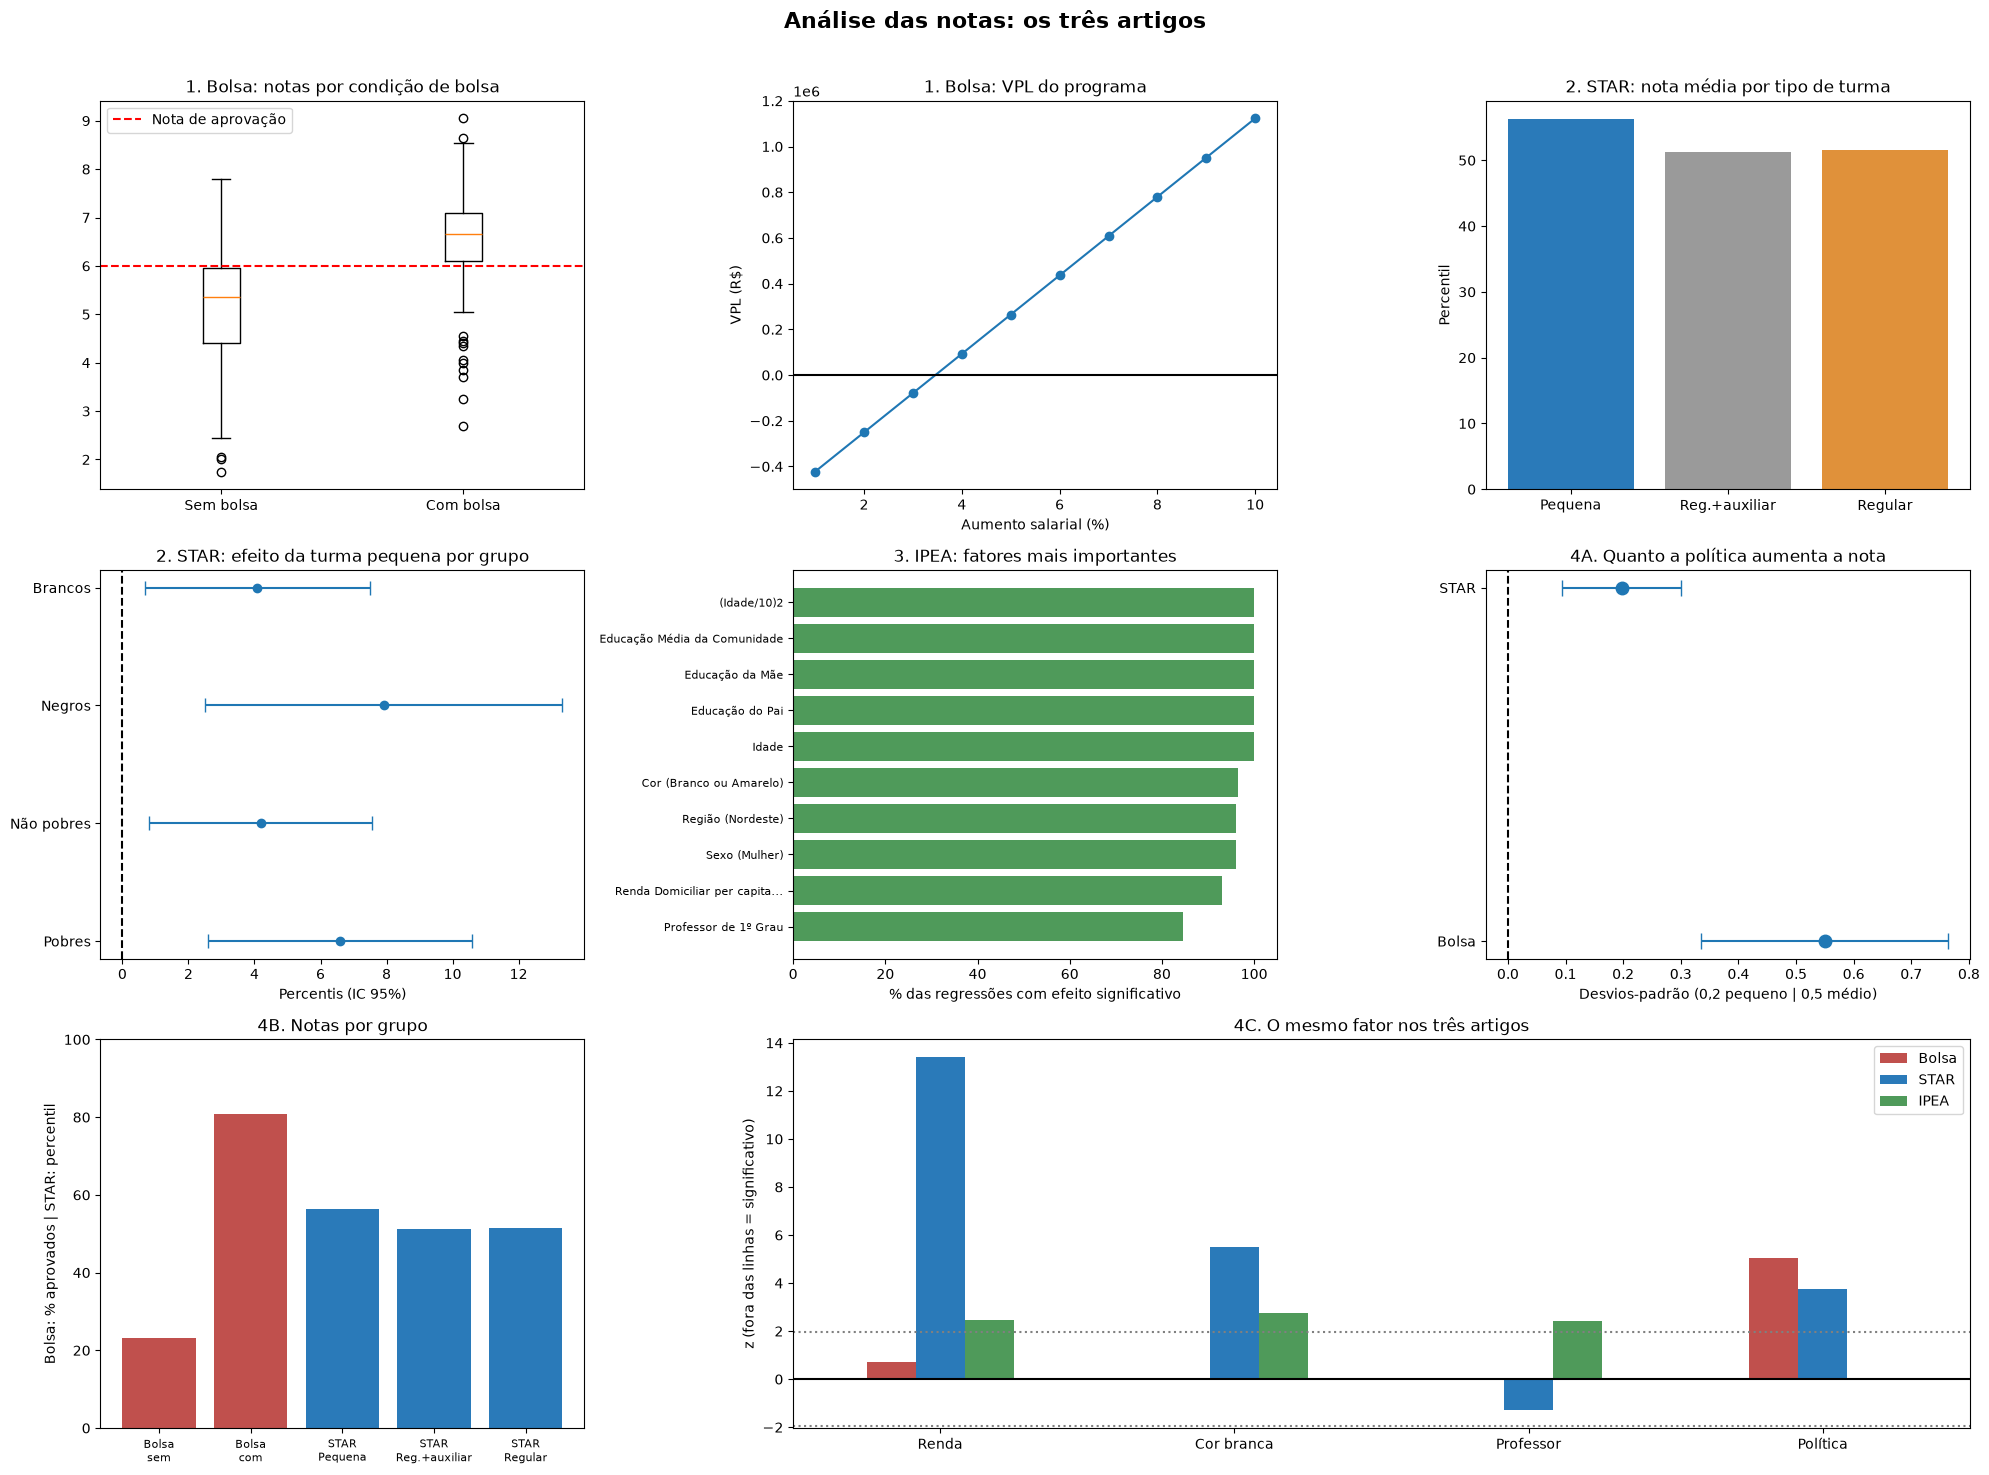

In [ ]:
if __name__ == "__main__":
    juntar()